In [96]:
pacman::p_load(dplyr,ggplot2,tidyr,stringr,patchwork)

In [97]:
## read in taxonomy linked to abundances
merged_w_tax = read.csv("../data/merged_salmon_abund_transcript_names_tax.tsv") %>%
    dplyr::filter(E.value<0.00001)

tax_abundances = read.csv("../data/merged_salmon_abund_transcript_names__.tsv")

In [98]:
## separate into taxonomic labels
merged_w_tax = merged_w_tax %>%
    tidyr::separate(full_classification,sep=";",into=c("Domain","Supergroup","Phylum",
                                                       "Class","Order","Family",
                                                       "Genus","Species")) %>%
    dplyr::mutate(Order=case_when(trimws(Order)=="Cryptophyceae_XXX"~"Cryptomonadales",
                            TRUE~trimws(Order)))

Warning message:
“Expected 8 pieces. Missing pieces filled with `NA` in 135399 rows [1, 2, 3, 4,
5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, ...].”


In [99]:
## read in environmental phosphate abundances
phos_ptown = read.csv("../data/phosphorus.csv")
phos_ptown = read.csv("../data/nutrients/CC_wet_chemistry_2000_2021.csv") %>%
    dplyr::mutate(Date=as.Date(STAT_ARRIV, format="%d-%b-%Y %H:%M:%S")) %>%
    dplyr::bind_rows(read.csv("../data/nutrients/CC_wet_chemistry_2022_2023.csv") %>%
                     dplyr::mutate(Date=as.Date(STAT_ARRIV, format="%Y-%m-%d")))

phos_ptown_dt = phos_ptown%>% dplyr::filter(PARAM_CODE=="PO4") %>% 
    dplyr::filter(DEPTH<5)
phos_ptown_dt = phos_ptown_dt %>% dplyr::group_by(Date,STAT_ID) %>%
    dplyr::summarize(phosphate = mean(FFU_RESULT))%>%
    dplyr::mutate(SampleDate = as.POSIXct(paste0(format(as.Date(Date, 
                                                                 format = "%Y-%m-%d"),"%Y-%m"),"-01"),
                                          format="%Y-%m-%d"))

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by Date and STAT_ID.
ℹ Output is grouped by Date.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(Date, STAT_ID))` for per-operation grouping
  (`?dplyr::dplyr_by`) instead.


In [100]:
## read in environmental nitrate/nitrite/ammonium abundances
nitr_ptown = read.csv("../data/nitrogen.csv")
nitr_ptown = read.csv("../data/CC_wet_chemistry_2000_2021.csv") %>%
    dplyr::mutate(Date=as.Date(STAT_ARRIV, format="%d-%b-%Y %H:%M:%S")) %>%
    dplyr::bind_rows(read.csv("../data/CC_wet_chemistry_2022_2023.csv") %>%
                     dplyr::mutate(Date=as.Date(STAT_ARRIV, format="%Y-%m-%d")))
nitr_ptown_dt = nitr_ptown%>% dplyr::filter(DEPTH<5)

nitr_ptown_dt = nitr_ptown_dt %>% dplyr::filter(PARAM_CODE %in% 
                                             c("NO2","NO3","NO3+NO2")) %>%
    dplyr::group_by(PARAM_CODE,STAT_ARRIV,STAT_ID,Date) %>%
    dplyr::summarize(FFU_RESULT = mean(FFU_RESULT,na.rm=TRUE)) %>%
    pivot_wider(id_cols = c("STAT_ARRIV","STAT_ID","Date"),names_from="PARAM_CODE",
                values_from="FFU_RESULT")

nitr_ptown_dt = nitr_ptown_dt %>% 
    dplyr::rename(c("NO3_NO2"="NO3+NO2")) %>%
    dplyr::mutate(nitrate = case_when(is.na(NO3_NO2) ~ NO3+NO2,
                                      TRUE~NO3_NO2))%>%
    dplyr::mutate(SampleDate = as.POSIXct(paste0(format(as.Date(Date, 
                                                                 format = "%Y-%m-%d"),"%Y-%m"),"-01"),
                                          format="%Y-%m-%d"))

ammon_ptown = read.csv("../data/nitrogen.csv")
ammon_ptown = read.csv("../data/CC_wet_chemistry_2000_2021.csv") %>%
    dplyr::mutate(Date=as.Date(STAT_ARRIV, format="%d-%b-%Y %H:%M:%S")) %>%
    dplyr::bind_rows(read.csv("../data/CC_wet_chemistry_2022_2023.csv") %>%
                     dplyr::mutate(Date=as.Date(STAT_ARRIV, format="%Y-%m-%d")))
ammon_ptown_dt = ammon_ptown %>% dplyr::filter(DEPTH<5)

ammon_ptown_dt = ammon_ptown_dt %>% dplyr::filter(PARAM_CODE %in% 
                                             c("NH4")) %>%
    dplyr::group_by(PARAM_CODE,STAT_ARRIV,STAT_ID,Date) %>%
    dplyr::summarize(FFU_RESULT = mean(FFU_RESULT,na.rm=TRUE)) %>%
    pivot_wider(id_cols = c("STAT_ARRIV","STAT_ID","Date"),names_from="PARAM_CODE",
                values_from="FFU_RESULT")

ammon_ptown_dt = ammon_ptown_dt %>% 
    dplyr::rename(c("ammonium"="NH4")) %>%
    dplyr::mutate(SampleDate = as.POSIXct(paste0(format(as.Date(Date, 
                                                                 format = "%Y-%m-%d"),"%Y-%m"),"-01"),
                                          format="%Y-%m-%d"))

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by PARAM_CODE, STAT_ARRIV, STAT_ID, and Date.
ℹ Output is grouped by PARAM_CODE, STAT_ARRIV, and STAT_ID.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(PARAM_CODE, STAT_ARRIV, STAT_ID, Date))` for
  per-operation grouping (`?dplyr::dplyr_by`) instead.
`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by PARAM_CODE, STAT_ARRIV, STAT_ID, and Date.
ℹ Output is grouped by PARAM_CODE, STAT_ARRIV, and STAT_ID.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(PARAM_CODE, STAT_ARRIV, STAT_ID, Date))` for
  per-operation grouping (`?dplyr::dplyr_by`) instead.


In [101]:
## to be used, a taxon has to either have the full set of P or N genes.
pass_threshold = merged_w_tax %>% dplyr::mutate(Order=trimws(Order)) %>%
    dplyr::filter(trimws(Phylum)%in%c("Ochrophyta","Dinoflagellata",
                                      "Haptophyta","Chlorophyta",
                                      "Rhodophyta","Cryptophyta"))%>%
    dplyr::group_by(Order) %>%
    dplyr::summarize(KO_merged=paste(sort(unique(KO)),collapse="|"),
                     num_KOs=length(unique(KO))) %>%
    dplyr::arrange(desc(num_KOs)) %>%
    dplyr::filter(num_KOs!=1) %>%
    dplyr::filter((grepl("K14430",KO_merged)&grepl("K14683",KO_merged))|
                  (grepl("K10534",KO_merged)&grepl("K02575",KO_merged))) %>%
    dplyr::filter(!is.na(Order)&!
                  (Order%in%c("Cyclotrichiida","Acanthoecida","Pedinellales",
                              "Flavobacteriales","Stramenopiles_XXX",
                              "Pinguiochrysidaceae")))

In [102]:
## to be used, a taxon has to either have the full set of P or N genes.
pass_threshold_both = merged_w_tax %>% dplyr::mutate(Order=trimws(Order)) %>%
    dplyr::filter(trimws(Phylum)%in%c("Ochrophyta","Dinoflagellata",
                                      "Haptophyta","Chlorophyta",
                                      "Rhodophyta","Cryptophyta"))%>%
    dplyr::group_by(Order) %>%
    dplyr::summarize(KO_merged=paste(sort(unique(KO)),collapse="|"),
                     num_KOs=length(unique(KO))) %>%
    dplyr::arrange(desc(num_KOs)) %>%
    dplyr::filter(num_KOs!=1) %>%
    dplyr::filter((grepl("K14430",KO_merged)&grepl("K14683",KO_merged))&
                  (grepl("K10534",KO_merged)&grepl("K02575",KO_merged))) %>%
    dplyr::filter(!is.na(Order)&!
                  (Order%in%c("Cyclotrichiida","Acanthoecida","Pedinellales",
                              "Flavobacteriales","Stramenopiles_XXX",
                              "Pinguiochrysidaceae")))

In [103]:
## for the P genes to be used, the set must appear in >30 samples
passing_orders = merged_w_tax %>%
    dplyr::mutate(Order=trimws(Order)) %>% dplyr::group_by(Order,KO,Sample)%>%
    dplyr::summarize(TPM = sum(V4)) %>%
    tidyr::separate(Sample,sep="_",into=c("SampleNum","Rep","Station","Year","Month"),remove=FALSE) %>%
    dplyr::mutate(transporter_annot=KO)%>%
    dplyr::mutate(Month = str_replace_all(Month, "SEPT", "SEP")) %>%
    dplyr::mutate(SampleDate=as.POSIXct(strptime(tolower(paste0(Year,"-",Month,"-01")),
                                                 format="%Y-%b-%d"))) %>%
    dplyr::left_join(phos_ptown_dt,by=c("Station"="STAT_ID","SampleDate")) %>%
    dplyr::filter((transporter_annot %in% c("K14430","K14683")))%>%
    dplyr::mutate(transporter_interp = case_when(transporter_annot=="K14430"~"low_affinity",
                                                 transporter_annot=="K14683"~"high_affinity")) %>%
    dplyr::mutate(propTPM=TPM) %>%
    tidyr::pivot_wider(id_cols=c("Station","Order","SampleDate","Sample","phosphate"),
                       names_from="transporter_interp",
                       values_from="propTPM") %>%
    dplyr::filter(!is.na(low_affinity)&!is.na(high_affinity)) %>%
    dplyr::group_by(Order) %>% dplyr::tally() %>% dplyr::filter(n>30)

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by Order, KO, and Sample.
ℹ Output is grouped by Order and KO.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(Order, KO, Sample))` for per-operation grouping
  (`?dplyr::dplyr_by`) instead.


In [104]:
## for the N genes to be used, the pair must be used in >30 samples.
passing_orders_n = merged_w_tax %>%
    dplyr::mutate(Order=trimws(Order)) %>% dplyr::group_by(Order,KO,Sample)%>%
    dplyr::summarize(TPM = sum(V4)) %>%
    tidyr::separate(Sample,sep="_",into=c("SampleNum","Rep","Station","Year","Month"),remove=FALSE) %>%
    dplyr::mutate(transporter_annot=KO)%>%
    dplyr::mutate(Month = str_replace_all(Month, "SEPT", "SEP")) %>%
    dplyr::mutate(SampleDate=as.POSIXct(strptime(tolower(paste0(Year,"-",Month,"-01")),
                                                 format="%Y-%b-%d"))) %>%
    dplyr::left_join(ammon_ptown_dt,by=c("Station"="STAT_ID","SampleDate")) %>%
    dplyr::left_join(nitr_ptown_dt,by=c("Station"="STAT_ID","SampleDate"))  %>%
    dplyr::filter((transporter_annot %in% c("K02575","K10534")))%>%
    dplyr::mutate(transporter_interp = case_when(transporter_annot=="K10534"~"low_affinity",
                                                 transporter_annot=="K02575"~"high_affinity")) %>%
    dplyr::mutate(propTPM=TPM) %>%
    tidyr::pivot_wider(id_cols=c("Station","Order","SampleDate","Sample","nitrate"),
                       names_from="transporter_interp",
                       values_from="propTPM") %>%
    dplyr::filter(!is.na(low_affinity)&!is.na(high_affinity)) %>%
    dplyr::group_by(Order) %>% dplyr::tally() %>% dplyr::filter(n>30)

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by Order, KO, and Sample.
ℹ Output is grouped by Order and KO.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(Order, KO, Sample))` for per-operation grouping
  (`?dplyr::dplyr_by`) instead.


In [105]:
intersect(intersect(pass_threshold_both$Order,passing_orders$Order),passing_orders_n$Order)

[1] "Bacillariales"        "Chaetocerotophycidae" "Coscinodiscales"     
 [4] "Cryptomonadales"      "Cymatosirales"        "Gonyaulacales"       
 [7] "Gymnodiniales"        "Hemiaulales"          "Leptocylindrales"    
[10] "Mamiellales"          "Peridiniales"         "Phaeocystales"       
[13] "Prymnesiales"         "Rhizosoleniales"      "Suessiales"          
[16] "Thalassiosirales"

In [106]:
## summarize by transporter and Order
summarized_transporter = merged_w_tax %>%
    dplyr::mutate(Order=trimws(Order),Phylum=trimws(Phylum)) %>% dplyr::group_by(Order,Phylum,KO,Sample)%>%
    dplyr::summarize(TPM = sum(V4)) %>%
    tidyr::separate(Sample,sep="_",into=c("SampleNum","Rep","Station","Year","Month"),remove=FALSE) %>%
    dplyr::mutate(transporter_annot=KO)%>%
    dplyr::mutate(Month = str_replace_all(Month, "SEPT", "SEP")) %>%
    dplyr::mutate(SampleDate=as.POSIXct(strptime(tolower(paste0(Year,"-",Month,"-01")),
                                                 format="%Y-%b-%d"))) %>%
    dplyr::filter((Order%in%pass_threshold$Order)&((Order%in%passing_orders$Order)))

for_calculation = summarized_transporter %>%
    dplyr::left_join(phos_ptown_dt,by=c("Station"="STAT_ID","SampleDate")) %>%
    dplyr::filter((transporter_annot %in% c("K14430","K14683")))%>%
    dplyr::mutate(transporter_interp = case_when(transporter_annot=="K14430"~"low_affinity",
                                                 transporter_annot=="K14683"~"high_affinity")) %>%
    dplyr::mutate(propTPM=TPM) %>%
    tidyr::pivot_wider(id_cols=c("Station","Order","SampleDate","Sample","phosphate"),
                       names_from="transporter_interp",
                       values_from="propTPM") %>%
    dplyr::mutate(low_affinity=case_when(is.na(low_affinity)~0,
                                         TRUE~low_affinity),
                  high_affinity=case_when(is.na(high_affinity)~0,
                                         TRUE~high_affinity)) %>%
    dplyr::group_by(Order) %>%
    dplyr::mutate(low_to_high = (high_affinity-low_affinity)/(low_affinity+high_affinity)) %>%
    dplyr::group_by(Order,phosphate,Station,SampleDate,Sample) %>%
    dplyr::summarize(low_to_high=mean(low_to_high))

stats_frame = data.frame()
for_paper_stats_frame = data.frame()
for (order_curr in unique(for_calculation$Order)) {
    subset_fr = for_calculation %>% dplyr::filter(Order==order_curr) %>%
        dplyr::filter(!is.na(phosphate)&!is.na(low_to_high)) %>%
        dplyr::mutate(phosphate = phosphate + 0.001)
    print(order_curr)
    spearman_corr = cor.test(subset_fr$phosphate,subset_fr$low_to_high,method="spearman")
    print(spearman_corr)
    linear_res = lm(subset_fr$low_to_high~log10(subset_fr$phosphate))
    linear_res = lm(subset_fr$low_to_high~subset_fr$phosphate)
    print(summary(linear_res))
    
    print(as.numeric(predict(linear_res)))
    min_y_pred <- min(predict(linear_res))
    max_y_pred <- max(predict(linear_res))
    max_y = max(subset_fr$low_to_high)
    min_y = min(subset_fr$low_to_high)
    half_decay_y <- 0#0.5#0.5#(min_y+max_y)/2 #0.5#(min_y+max_y)/2 #(min_y_pred) / 2 # y value at 1/2 of the max.
    intercept <- as.numeric(coef(linear_res)[1])
    slope <- as.numeric(coef(linear_res)[2])
    print(half_decay_y)
    print(intercept)
    print(slope)
    log10_x_at_half_decay <- (half_decay_y - intercept) / slope
    print(log10_x_at_half_decay)
    
    x_at_half_decay <- 10^(log10_x_at_half_decay)
    
    print(paste0("x intercept is ",-linear_res$coefficients[1]/linear_res$coefficients[2]))
    stats_frame = stats_frame %>%
        dplyr::bind_rows(data.frame("Taxon"=order_curr,
                                    "X_intercept"=10^(-linear_res$coefficients[1]/linear_res$coefficients[2]),
                                    "half_decay_y"=half_decay_y,
                                    "x_at_half_decay"=x_at_half_decay,
                                    "linear_R_square"=summary(linear_res)$r.squared,
                                    "linear_p_val"=summary(linear_res)$coefficients[,4][2],
                                    "linear_slope"=linear_res$coefficients[2],
                                    "linear_intercept"=linear_res$coefficients[1],
                                    "spearman_corr" = spearman_corr$estimate,
                                    "spearman_p_val" = spearman_corr$p.value))
    
    
    for_paper_stats_frame = for_paper_stats_frame %>%
        dplyr::bind_rows(data.frame("Taxon"=order_curr,
                                    "estimated_parameter"=log10_x_at_half_decay,
                                    "exponential_slope"=linear_res$coefficients[2],
                                    "exponential_intercept"=linear_res$coefficients[1],
                                    "exponential_p_val"=summary(linear_res)$coefficients[,4][2],
                                    "exponential_R_square"=summary(linear_res)$r.squared,
                                    "spearman_corr" = spearman_corr$estimate,
                                    "spearman_p_val" = spearman_corr$p.value))
                                    
}

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by Order, Phylum, KO, and Sample.
ℹ Output is grouped by Order, Phylum, and KO.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(Order, Phylum, KO, Sample))` for per-operation
  grouping (`?dplyr::dplyr_by`) instead.
`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by Order, phosphate, Station, SampleDate, and
  Sample.
ℹ Output is grouped by Order, phosphate, Station, and SampleDate.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(Order, phosphate, Station, SampleDate, Sample))` for
  per-operation grouping (`?dplyr::dplyr_by`) instead.


[1] "Bacillariales"


Warning message in cor.test.default(subset_fr$phosphate, subset_fr$low_to_high, :
“Cannot compute exact p-value with ties”



	Spearman's rank correlation rho

data:  subset_fr$phosphate and subset_fr$low_to_high
S = 83058, p-value = 0.04865
alternative hypothesis: true rho is not equal to 0
sample estimates:
       rho 
-0.2300354 



Warning message in eval(predvars, data, env):
“NaNs produced”


...


Call:
lm(formula = subset_fr$low_to_high ~ subset_fr$phosphate)

Residuals:
     Min       1Q   Median       3Q      Max 
-0.71581 -0.10113  0.07058  0.13476  0.19778 

Coefficients:
                    Estimate Std. Error t value Pr(>|t|)    
(Intercept)          0.80502    0.03431  23.463   <2e-16 ***
subset_fr$phosphate  0.31044    0.12314   2.521   0.0138 *  
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.2075 on 75 degrees of freedom
Multiple R-squared:  0.07812,	Adjusted R-squared:  0.06583 
F-statistic: 6.356 on 1 and 75 DF,  p-value: 0.01383

 [1] 0.8022216 0.8022216 0.8022216 0.8093617 0.8093617 0.8093617 0.8112243
 [8] 0.8112243 0.8112243 0.8118452 0.8118452 0.8118452 0.8127765 0.8127765
[15] 0.8127765 0.8180540 0.8255045 0.8255045 0.8255045 0.8258149 0.8258149
[22] 0.8258149 0.8289193 0.8289193 0.8289193 0.8335759 0.8335759 0.8335759
[29] 0.8357490 0.8357490 0.8357490 0.8391638 0.8391638 0.8391638 0.8419578
[36] 0.8419578 0.84

Warning message in cor.test.default(subset_fr$phosphate, subset_fr$low_to_high, :
“Cannot compute exact p-value with ties”



	Spearman's rank correlation rho

data:  subset_fr$phosphate and subset_fr$low_to_high
S = 138975, p-value = 4.199e-10
alternative hypothesis: true rho is not equal to 0
sample estimates:
       rho 
-0.6288681 



Warning message in eval(predvars, data, env):
“NaNs produced”



Call:
lm(formula = subset_fr$low_to_high ~ subset_fr$phosphate)

Residuals:
     Min       1Q   Median       3Q      Max 
-0.58103 -0.15480  0.00437  0.18839  0.48003 

Coefficients:
                    Estimate Std. Error t value Pr(>|t|)    
(Intercept)          0.71822    0.03498  20.531  < 2e-16 ***
subset_fr$phosphate -1.11275    0.12344  -9.014 1.01e-13 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.2175 on 78 degrees of freedom
Multiple R-squared:  0.5102,	Adjusted R-squared:  0.5039 
F-statistic: 81.26 on 1 and 78 DF,  p-value: 1.012e-13

 [1]  0.72823107  0.72823107  0.72823107  0.70263787  0.70263787  0.70263787
 [7]  0.69596139  0.69596139  0.69596139  0.69373589  0.69373589  0.69373589
[13]  0.69039765  0.69039765  0.69039765  0.67148094  0.67148094  0.67148094
[19]  0.64477499  0.64477499  0.64477499  0.64366224  0.64366224  0.64366224
[25]  0.63253477  0.63253477  0.63253477  0.61584355  0.61584355  0.61584355
[31]  0.6

In [107]:
for_paper_stats_frame

,Taxon,estimated_parameter,exponential_slope,exponential_intercept,exponential_p_val,exponential_R_square,spearman_corr,spearman_p_val
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
subset_fr$phosphate...1,Bacillariales,0.23859715,-0.600582917,0.143297374,1.139239e-01,3.434482e-02,-0.23003537,4.864638e-02
subset_fr$phosphate...2,Chaetocerotophycidae,0.48871507,-0.956386965,0.467400719,1.469228e-03,1.223678e-01,-0.50594739,1.688701e-06
subset_fr$phosphate...3,Coscinodiscales,1.30207709,0.736328565,-0.958756554,2.538841e-05,2.223817e-01,0.41872638,2.270952e-04
subset_fr$phosphate...4,Cryptomonadales,2.17048228,0.105015342,-0.227933939,8.075808e-01,1.129133e-03,0.02332679,8.657608e-01
subset_fr$phosphate...5,Cymatosirales,-0.48331841,-0.579809844,-0.280232772,1.707586e-01,2.701794e-02,-0.19039731,1.117388e-01
subset_fr$phosphate...6,Gonyaulacales,0.51249937,-0.245710422,0.125926435,3.333840e-01,1.200074e-02,-0.08657462,4.451085e-01
subset_fr$phosphate...7,Gymnodiniales,0.70103822,-0.853139832,0.598083633,3.520673e-04,1.519086e-01,-0.41140914,1.499390e-04
subset_fr$phosphate...8,Hemiaulales,0.02780457,-3.371267031,0.093736641,2.568327e-04,2.496798e-01,-0.58291789,1.108213e-05
subset_fr$phosphate...9,Leptocylindrales,0.33780248,-0.908067318,0.306747393,1.029813e-02,8.678814e-02,-0.37640450,8.737253e-04


In [108]:
for_paper_stats_frame %>% dplyr::filter(exponential_p_val < 0.11) %>%
    dplyr::select(Taxon,estimated_parameter,exponential_p_val,exponential_R_square)

,Taxon,estimated_parameter,exponential_p_val,exponential_R_square
,<chr>,<dbl>,<dbl>,<dbl>
subset_fr$phosphate...1,Chaetocerotophycidae,0.48871507,1.469228e-03,0.12236778
subset_fr$phosphate...2,Coscinodiscales,1.30207709,2.538841e-05,0.22238173
subset_fr$phosphate...3,Gymnodiniales,0.70103822,3.520673e-04,0.15190858
subset_fr$phosphate...4,Hemiaulales,0.02780457,2.568327e-04,0.24967979
subset_fr$phosphate...5,Leptocylindrales,0.33780248,1.029813e-02,0.08678814
subset_fr$phosphate...6,Mamiellales,0.00834472,3.091310e-04,0.15456758
subset_fr$phosphate...7,Parmales,0.52845062,8.334541e-06,0.23957304
subset_fr$phosphate...8,Phaeocystales,0.25934911,6.706191e-08,0.31677423
subset_fr$phosphate...9,Rhizosoleniales,0.84905727,1.891021e-02,0.07517211


`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by Order, phosphate, Station, SampleDate, and
  Sample.
ℹ Output is grouped by Order, phosphate, Station, and SampleDate.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(Order, phosphate, Station, SampleDate, Sample))` for
  per-operation grouping (`?dplyr::dplyr_by`) instead.
Warning message:
“Removed 338 rows containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 7 rows containing missing values or values outside the scale range
(`geom_line()`).”
Warning message:
“Removed 338 rows containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 7 rows containing missing values or values outside the scale range
(`geom_line()`).”


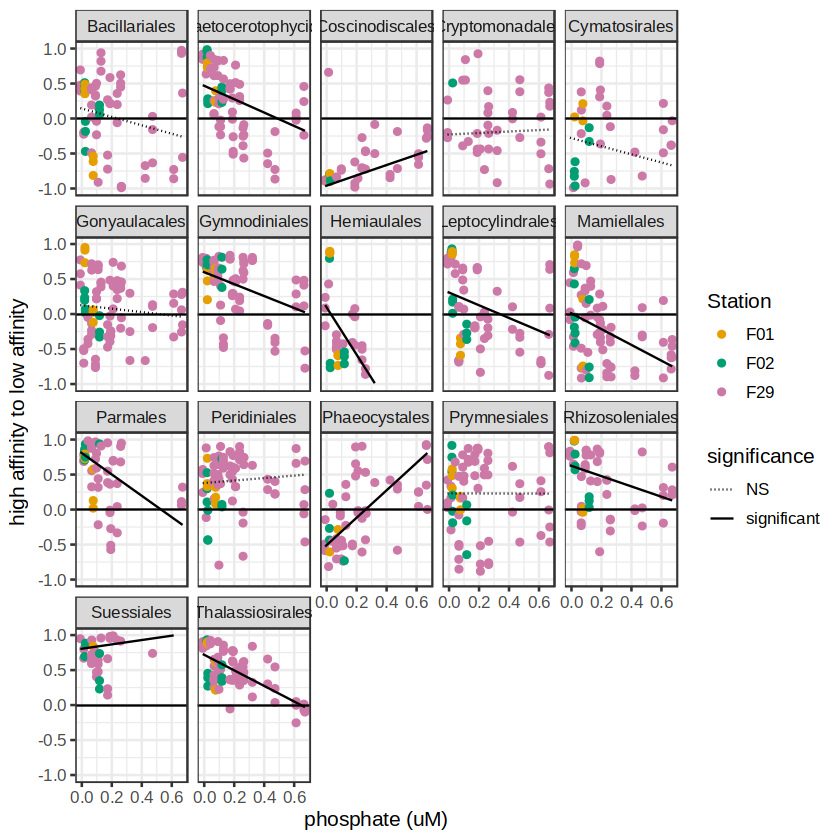

In [109]:
ggplot(summarized_transporter %>%
    dplyr::left_join(phos_ptown_dt,by=c("Station"="STAT_ID","SampleDate")) %>%
    dplyr::filter((transporter_annot %in% c("K14430","K14683")))%>%
    dplyr::mutate(transporter_interp = case_when(transporter_annot=="K14430"~"low_affinity",
                                                 transporter_annot=="K14683"~"high_affinity")) %>%
    tidyr::pivot_wider(id_cols=c("Station","Order","SampleDate","Sample","phosphate"),
                       names_from="transporter_interp",
                       values_from="TPM") %>%
    dplyr::group_by(Order) %>%
    dplyr::mutate(low_to_high = (high_affinity-low_affinity)/(low_affinity+high_affinity)) %>%
    dplyr::group_by(Order,phosphate,Station,SampleDate,Sample) %>%
    dplyr::summarize(low_to_high=mean(low_to_high)) %>%
    dplyr::left_join(stats_frame,by=c("Order"="Taxon")) %>%
    dplyr::mutate(modeled_value = linear_intercept + linear_slope*phosphate) %>%
    dplyr::mutate(significance=case_when(linear_p_val<0.11~"significant",
                                         TRUE ~ "NS"))) +
    geom_point(aes(x=phosphate,color=Station,y=low_to_high)) +
    geom_line(aes(x=phosphate,y=modeled_value,linetype=significance)) +
    scale_linetype_manual(values=c("dotted","solid"),
                          breaks=c("NS","significant")) + 
    geom_hline(aes(yintercept=0)) + xlab("phosphate (uM)") + 
    scale_color_manual(values=c("#E69F00","#009E73","#CC79A7"),
                       breaks=c("F01","F02","F29")) + 
    #geom_hline(aes(yintercept=0.5),linetype="dashed") + 
    theme_bw(base_size=12) + ylim(c(-1,1))+
    facet_wrap(~Order) + ylab("high affinity to low affinity") 

ggsave("../figures/phosphate_transporter_linear.pdf",width=10,height=8,units="in")

In [110]:
phosphate_small = ggplot(summarized_transporter %>%
    dplyr::left_join(phos_ptown_dt,by=c("Station"="STAT_ID","SampleDate")) %>%
    dplyr::filter((transporter_annot %in% c("K14430","K14683")))%>%
    dplyr::filter(Order%in%c("Chaetocerotophycidae","Gymnodiniales",
                             "Leptocylindrales","Mamiellales","Thalassiosirales")) %>%
    dplyr::mutate(transporter_interp = case_when(transporter_annot=="K14430"~"low_affinity",
                                                 transporter_annot=="K14683"~"high_affinity")) %>%
    tidyr::pivot_wider(id_cols=c("Station","Order","SampleDate","Sample","phosphate"),
                       names_from="transporter_interp",
                       values_from="TPM") %>%
    dplyr::group_by(Order) %>%
    dplyr::mutate(low_to_high = (high_affinity-low_affinity)/(low_affinity+high_affinity)) %>%
    dplyr::group_by(Order,phosphate,Station,SampleDate,Sample) %>%
    dplyr::summarize(low_to_high=mean(low_to_high)) %>%
    dplyr::left_join(stats_frame,by=c("Order"="Taxon")) %>%
    dplyr::mutate(modeled_value = linear_intercept + linear_slope*phosphate) %>%
    dplyr::mutate(significance=case_when(linear_p_val<0.11~"significant",
                                         TRUE ~ "NS"))) +
    geom_point(aes(x=phosphate,color=Station,y=low_to_high)) +
    geom_line(aes(x=phosphate,y=modeled_value,linetype=significance)) +
    scale_linetype_manual(values=c("dotted","solid"),
                          breaks=c("NS","significant")) + 
    scale_color_manual(values=c("#E69F00","#009E73","#CC79A7"),
                       breaks=c("F01","F02","F29")) + 
    geom_hline(aes(yintercept=0)) + 
    theme_bw(base_size=12) + 
    facet_wrap(~Order,scales="free_y",nrow=1) + ylab("high affinity to low affinity") 

ggsave("../figures/phosphate_transporter_linear_small.png",plot=phosphate_small,width=8,height=6,units="in")

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by Order, phosphate, Station, SampleDate, and
  Sample.
ℹ Output is grouped by Order, phosphate, Station, and SampleDate.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(Order, phosphate, Station, SampleDate, Sample))` for
  per-operation grouping (`?dplyr::dplyr_by`) instead.
Warning message:
“Removed 46 rows containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 3 rows containing missing values or values outside the scale range
(`geom_line()`).”


In [111]:
## summarize by transporter and Order
summarized_transporter = merged_w_tax %>%
    dplyr::mutate(Order=trimws(Order),Phylum=trimws(Phylum)) %>% dplyr::group_by(Order,Phylum,KO,Sample)%>%
    dplyr::summarize(TPM = sum(V4)) %>%
    tidyr::separate(Sample,sep="_",into=c("SampleNum","Rep","Station","Year","Month"),remove=FALSE) %>%
    dplyr::mutate(transporter_annot=KO)%>%
    dplyr::mutate(Month = str_replace_all(Month, "SEPT", "SEP")) %>%
    dplyr::mutate(SampleDate=as.POSIXct(strptime(tolower(paste0(Year,"-",Month,"-01")),
                                                 format="%Y-%b-%d"))) %>%
    dplyr::filter((Order%in%pass_threshold$Order)&((Order%in%passing_orders_n$Order)))

for_calculation = summarized_transporter %>%
    dplyr::left_join(ammon_ptown_dt,by=c("Station"="STAT_ID","SampleDate")) %>%
    dplyr::left_join(nitr_ptown_dt,by=c("Station"="STAT_ID","SampleDate"))  %>%
    dplyr::filter((transporter_annot %in% c("K10534","K02575")))%>%
    dplyr::mutate(transporter_interp = case_when(transporter_annot=="K10534"~"low_affinity",
                                                 transporter_annot=="K02575"~"high_affinity")) %>%
    dplyr::group_by(Station,Order,SampleDate,nitrate,ammonium,Sample,transporter_interp) %>%
    dplyr::mutate(propTPM=TPM) %>%
    tidyr::pivot_wider(id_cols=c("Station","Order","SampleDate","Sample","nitrate","ammonium"),
                       names_from="transporter_interp",
                       values_from="propTPM") %>%
    dplyr::mutate(low_affinity=case_when(is.na(low_affinity)~0,
                                         TRUE~low_affinity),
                  high_affinity=case_when(is.na(high_affinity)~0,
                                         TRUE~high_affinity)) %>%
    dplyr::group_by(Order) %>%
    dplyr::mutate(low_to_high = (high_affinity-low_affinity)/(low_affinity+high_affinity)) %>%
    dplyr::group_by(Order,nitrate,ammonium,Station,SampleDate,Sample) %>%
    dplyr::summarize(low_to_high=mean(low_to_high))

stats_frame = data.frame()
for_paper_stats_frame_n = data.frame()
for (order_curr in unique(for_calculation$Order)) {
    subset_fr = for_calculation %>% dplyr::filter(Order==order_curr) %>%
        dplyr::filter(!is.na(ammonium)&!is.na(low_to_high)&!is.na(nitrate)) %>%
        dplyr::mutate(summed_n = ammonium + nitrate)
    print(order_curr)
    spearman_corr = cor.test(subset_fr$summed_n,subset_fr$low_to_high,method="spearman")
    print(spearman_corr)
    linear_res = lm(subset_fr$low_to_high~log10(subset_fr$summed_n))
    linear_res = lm(subset_fr$low_to_high~log10(subset_fr$summed_n))
    print(summary(linear_res))
    
    print(as.numeric(predict(linear_res)))
    min_y_pred <- min(predict(linear_res))
    max_y_pred <- max(predict(linear_res))
    max_y = max(subset_fr$low_to_high)
    min_y = min(subset_fr$low_to_high)
    half_decay_y <- -0.5#0.5#0.5#(min_y+max_y)/2 #0.5#(min_y+max_y)/2 #(min_y_pred) / 2 # y value at 1/2 of the max.
    intercept <- as.numeric(coef(linear_res)[1])
    slope <- as.numeric(coef(linear_res)[2])
    print(half_decay_y)
    print(intercept)
    print(slope)
    log10_x_at_half_decay <- (half_decay_y - intercept) / slope
    print(log10_x_at_half_decay)
    
    x_at_half_decay <- 10^(log10_x_at_half_decay)
    
    print(paste0("x intercept is ",-linear_res$coefficients[1]/linear_res$coefficients[2]))
    stats_frame = stats_frame %>%
        dplyr::bind_rows(data.frame("Taxon"=order_curr,
                                    "X_intercept"=10^(-linear_res$coefficients[1]/linear_res$coefficients[2]),
                                    "half_decay_y"=half_decay_y,
                                    "x_at_half_decay"=x_at_half_decay,
                                    "linear_R_square"=summary(linear_res)$r.squared,
                                    "linear_p_val"=summary(linear_res)$coefficients[,4][2],
                                    "linear_slope"=linear_res$coefficients[2],
                                    "linear_intercept"=linear_res$coefficients[1],
                                    "spearman_corr" = spearman_corr$estimate,
                                    "spearman_p_val" = spearman_corr$p.value))
    
    
    for_paper_stats_frame_n = for_paper_stats_frame_n %>%
        dplyr::bind_rows(data.frame("Taxon"=order_curr,
                                    "estimated_parameter"=x_at_half_decay,
                                    "exponential_slope"=linear_res$coefficients[2],
                                    "exponential_intercept"=linear_res$coefficients[1],
                                    "exponential_p_val"=summary(linear_res)$coefficients[,4][2],
                                    "exponential_R_square"=summary(linear_res)$r.squared,
                                    "spearman_corr" = spearman_corr$estimate,
                                    "spearman_p_val" = spearman_corr$p.value))
                                    
}

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by Order, Phylum, KO, and Sample.
ℹ Output is grouped by Order, Phylum, and KO.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(Order, Phylum, KO, Sample))` for per-operation
  grouping (`?dplyr::dplyr_by`) instead.
`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by Order, nitrate, ammonium, Station,
  SampleDate, and Sample.
ℹ Output is grouped by Order, nitrate, ammonium, Station, and SampleDate.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(Order, nitrate, ammonium, Station, SampleDate,
  Sample))` for per-operation grouping (`?dplyr::dplyr_by`) instead.


[1] "Bacillariales"


Warning message in cor.test.default(subset_fr$summed_n, subset_fr$low_to_high, method = "spearman"):
“Cannot compute exact p-value with ties”



	Spearman's rank correlation rho

data:  subset_fr$summed_n and subset_fr$low_to_high
S = 9254, p-value = 0.001001
alternative hypothesis: true rho is not equal to 0
sample estimates:
       rho 
-0.5464646 


Call:
lm(formula = subset_fr$low_to_high ~ log10(subset_fr$summed_n))

Residuals:
    Min      1Q  Median      3Q     Max 
-0.7622 -0.2719 -0.1211  0.4758  0.7430 

Coefficients:
                          Estimate Std. Error t value Pr(>|t|)    
(Intercept)               -0.33730    0.09501  -3.550 0.001252 ** 
log10(subset_fr$summed_n) -0.48117    0.12986  -3.705 0.000822 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.4471 on 31 degrees of freedom
Multiple R-squared:  0.307,	Adjusted R-squared:  0.2846 
F-statistic: 13.73 on 1 and 31 DF,  p-value: 0.0008222

 [1]  0.26995125  0.26995125  0.26995125 -0.04709912 -0.04709912 -0.04709912
 [7] -0.05755805 -0.05755805 -0.05755805  0.25413759  0.25413759  0.25413759
[13] -0.31271008 

Warning message in cor.test.default(subset_fr$summed_n, subset_fr$low_to_high, method = "spearman"):
“Cannot compute exact p-value with ties”


...


	Spearman's rank correlation rho

data:  subset_fr$summed_n and subset_fr$low_to_high
S = 1727.7, p-value = 0.5051
alternative hypothesis: true rho is not equal to 0
sample estimates:
      rho 
0.1463961 


Call:
lm(formula = subset_fr$low_to_high ~ log10(subset_fr$summed_n))

Residuals:
    Min      1Q  Median      3Q     Max 
-0.7027 -0.6719 -0.1952  0.3299  1.3187 

Coefficients:
                          Estimate Std. Error t value Pr(>|t|)  
(Intercept)               -0.33838    0.16339  -2.071   0.0509 .
log10(subset_fr$summed_n) -0.03257    0.24965  -0.130   0.8974  
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.714 on 21 degrees of freedom
Multiple R-squared:  0.0008099,	Adjusted R-squared:  -0.04677 
F-statistic: 0.01702 on 1 and 21 DF,  p-value: 0.8974

 [1] -0.2972729 -0.2972729 -0.3187347 -0.3187347 -0.3194427 -0.3194427
 [7] -0.3194427 -0.3367145 -0.3195395 -0.3195395 -0.3195395 -0.3227943
[13] -0.3227943 -0.3227943 -0.323

Warning message in cor.test.default(subset_fr$summed_n, subset_fr$low_to_high, method = "spearman"):
“Cannot compute exact p-value with ties”



	Spearman's rank correlation rho

data:  subset_fr$summed_n and subset_fr$low_to_high
S = 8591.6, p-value = 0.01125
alternative hypothesis: true rho is not equal to 0
sample estimates:
       rho 
-0.4357628 


Call:
lm(formula = subset_fr$low_to_high ~ log10(subset_fr$summed_n))

Residuals:
     Min       1Q   Median       3Q      Max 
-0.62290 -0.13170  0.00554  0.17982  0.51551 

Coefficients:
                          Estimate Std. Error t value Pr(>|t|)    
(Intercept)               -0.39367    0.05655  -6.962 8.22e-08 ***
log10(subset_fr$summed_n) -0.36971    0.07729  -4.784 3.99e-05 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.2661 on 31 degrees of freedom
Multiple R-squared:  0.4247,	Adjusted R-squared:  0.4061 
F-statistic: 22.88 on 1 and 31 DF,  p-value: 3.989e-05

 [1]  0.07290689  0.07290689  0.07290689 -0.17069686 -0.17069686 -0.17069686
 [7] -0.17873291 -0.17873291 -0.17873291  0.06075657  0.06075657  0.06075657
[13] 

Warning message in cor.test.default(subset_fr$summed_n, subset_fr$low_to_high, method = "spearman"):
“Cannot compute exact p-value with ties”



	Spearman's rank correlation rho

data:  subset_fr$summed_n and subset_fr$low_to_high
S = 2777.9, p-value = 0.8073
alternative hypothesis: true rho is not equal to 0
sample estimates:
       rho 
0.05027584 


Call:
lm(formula = subset_fr$low_to_high ~ log10(subset_fr$summed_n))

Residuals:
     Min       1Q   Median       3Q      Max 
-0.94333 -0.59542 -0.07637  0.52910  1.11351 

Coefficients:
                          Estimate Std. Error t value Pr(>|t|)
(Intercept)                -0.1227     0.2387  -0.514    0.612
log10(subset_fr$summed_n)  -0.1806     0.3172  -0.569    0.574

Residual standard error: 0.6996 on 24 degrees of freedom
Multiple R-squared:  0.01333,	Adjusted R-squared:  -0.02778 
F-statistic: 0.3243 on 1 and 24 DF,  p-value: 0.5743

 [1]  0.105186063  0.105186063  0.105186063 -0.013815083 -0.013815083
 [6] -0.013815083 -0.017740719  0.099250593  0.099250593  0.099250593
[11] -0.113509051 -0.113509051 -0.113509051 -0.002972272 -0.002972272
[16] -0.002972272 -0.0182773

In [113]:
for_paper_stats_frame_n %>%
    dplyr::select(Taxon,estimated_parameter,exponential_p_val,exponential_R_square)

,Taxon,estimated_parameter,exponential_p_val,exponential_R_square
,<chr>,<dbl>,<dbl>,<dbl>
log10(subset_fr$summed_n)...1,Bacillariales,2.178395e+00,8.222294e-04,0.3069581536
log10(subset_fr$summed_n)...2,Chaetocerotophycidae,6.691966e-02,1.519176e-02,0.1756598747
log10(subset_fr$summed_n)...3,Chromulinales,3.256064e-09,6.543947e-01,0.0065481580
log10(subset_fr$summed_n)...4,Coccolithales,8.206233e-01,2.152454e-01,0.0490973534
log10(subset_fr$summed_n)...5,Coscinodiscales,3.329756e+02,2.135044e-01,0.0510947409
log10(subset_fr$summed_n)...6,Cryptomonadales,2.138761e-01,6.198879e-02,0.1078985041
log10(subset_fr$summed_n)...7,Cymatosirales,1.316486e-02,7.114563e-01,0.0044754465
log10(subset_fr$summed_n)...8,Eupodiscales,5.579569e-01,1.204083e-01,0.0869729444
log10(subset_fr$summed_n)...9,Florenciellales,5.713316e+01,1.841146e-02,0.1664927551


In [114]:
for_paper_stats_frame_n %>% dplyr::filter(exponential_p_val < 0.11) %>%
    dplyr::select(Taxon,estimated_parameter,exponential_p_val,exponential_R_square)

,Taxon,estimated_parameter,exponential_p_val,exponential_R_square
,<chr>,<dbl>,<dbl>,<dbl>
log10(subset_fr$summed_n)...1,Bacillariales,2.178395e+00,8.222294e-04,0.30695815
log10(subset_fr$summed_n)...2,Chaetocerotophycidae,6.691966e-02,1.519176e-02,0.17565987
log10(subset_fr$summed_n)...3,Cryptomonadales,2.138761e-01,6.198879e-02,0.10789850
log10(subset_fr$summed_n)...4,Florenciellales,5.713316e+01,1.841146e-02,0.16649276
log10(subset_fr$summed_n)...5,Gonyaulacales,2.093648e-06,1.135687e-03,0.29324617
log10(subset_fr$summed_n)...6,Gymnodiniales,8.188421e-02,3.769752e-03,0.24042164
log10(subset_fr$summed_n)...7,Isochrysidales,1.838819e+00,1.431081e-05,0.46027035
log10(subset_fr$summed_n)...8,Leptocylindrales,6.682673e-01,2.691629e-05,0.43859170
log10(subset_fr$summed_n)...9,Lithodesmiales,4.521901e+00,6.275150e-02,0.11073312


`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by Order, summed_n, Station, SampleDate, and
  Sample.
ℹ Output is grouped by Order, summed_n, Station, and SampleDate.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(Order, summed_n, Station, SampleDate, Sample))` for
  per-operation grouping (`?dplyr::dplyr_by`) instead.
Warning message:
“Removed 1578 rows containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 86 rows containing missing values or values outside the scale range
(`geom_line()`).”
Warning message:
“Removed 1578 rows containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 86 rows containing missing values or values outside the scale range
(`geom_line()`).”


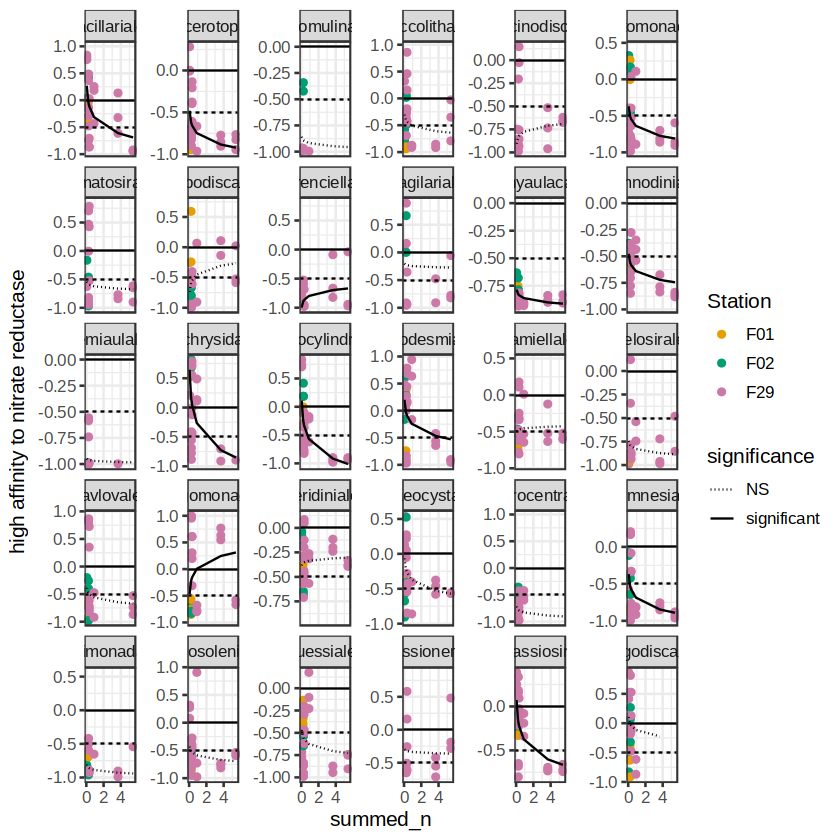

In [115]:
ggplot(summarized_transporter %>%
    dplyr::left_join(ammon_ptown_dt,by=c("Station"="STAT_ID","SampleDate")) %>%
    dplyr::left_join(nitr_ptown_dt,by=c("Station"="STAT_ID","SampleDate"))  %>%
    dplyr::mutate(summed_n=nitrate+ammonium) %>%
    dplyr::filter((transporter_annot %in% c("K10534","K02575")))%>%
    dplyr::mutate(transporter_interp = case_when(transporter_annot=="K10534"~"low_affinity",
                                                 transporter_annot=="K02575"~"high_affinity")) %>%
    tidyr::pivot_wider(id_cols=c("Station","Order","SampleDate","Sample","summed_n"),
                       names_from="transporter_interp",
                       values_from="TPM") %>%
    dplyr::group_by(Order) %>%
    dplyr::mutate(low_to_high = (high_affinity-low_affinity)/(low_affinity+high_affinity)) %>%
    dplyr::group_by(Order,summed_n,Station,SampleDate,Sample) %>%
    dplyr::summarize(low_to_high=mean(low_to_high)) %>%
    dplyr::left_join(stats_frame,by=c("Order"="Taxon")) %>%
    dplyr::mutate(modeled_value = linear_intercept + linear_slope*log10(summed_n)) %>%
    dplyr::mutate(significance=case_when(linear_p_val<0.11~"significant",
                                         TRUE ~ "NS"))) +
    geom_point(aes(x=summed_n,color=Station,y=low_to_high)) +
    geom_line(aes(x=summed_n,y=modeled_value,linetype=significance)) +
    scale_linetype_manual(values=c("dotted","solid"),
                          breaks=c("NS","significant")) + 
    scale_color_manual(values=c("#E69F00","#009E73","#CC79A7"),
                       breaks=c("F01","F02","F29")) + 
    geom_hline(aes(yintercept=0)) + 
    geom_hline(aes(yintercept=-0.5),linetype="dashed") + 
    theme_bw(base_size=12) + 
    facet_wrap(~Order,scales="free_y") + ylab("high affinity to nitrate reductase") 

ggsave("../figures/nitrogen_transporter_affinity.pdf",width=12,height=8,units="in")

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by Order, summed_n, Station, SampleDate, and
  Sample.
ℹ Output is grouped by Order, summed_n, Station, and SampleDate.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(Order, summed_n, Station, SampleDate, Sample))` for
  per-operation grouping (`?dplyr::dplyr_by`) instead.
Warning message:
“Removed 254 rows containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 102 rows containing missing values or values outside the scale range
(`geom_line()`).”


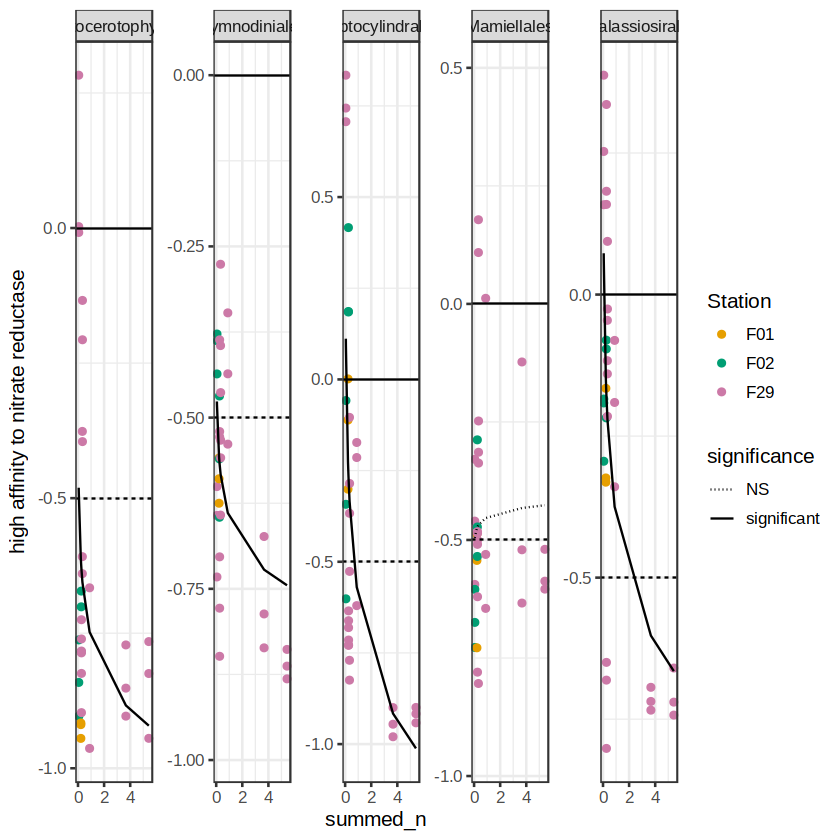

In [92]:
n_mini = ggplot(summarized_transporter %>%
    dplyr::left_join(ammon_ptown_dt,by=c("Station"="STAT_ID","SampleDate")) %>%
    dplyr::left_join(nitr_ptown_dt,by=c("Station"="STAT_ID","SampleDate"))  %>%
    dplyr::mutate(summed_n=nitrate+ammonium) %>%
    dplyr::filter(Order%in%c("Chaetocerotophycidae","Gymnodiniales",
                             "Leptocylindrales","Mamiellales","Thalassiosirales")) %>%
    dplyr::filter((transporter_annot %in% c("K10534","K02575")))%>%
    dplyr::mutate(transporter_interp = case_when(transporter_annot=="K10534"~"low_affinity",
                                                 transporter_annot=="K02575"~"high_affinity")) %>%
    tidyr::pivot_wider(id_cols=c("Station","Order","SampleDate","Sample","summed_n"),
                       names_from="transporter_interp",
                       values_from="TPM") %>%
    dplyr::group_by(Order) %>%
    dplyr::mutate(low_to_high = (high_affinity-low_affinity)/(low_affinity+high_affinity)) %>%
    dplyr::group_by(Order,summed_n,Station,SampleDate,Sample) %>%
    dplyr::summarize(low_to_high=mean(low_to_high)) %>%
    dplyr::left_join(stats_frame,by=c("Order"="Taxon")) %>%
    dplyr::mutate(modeled_value = linear_intercept + linear_slope*log10(summed_n)) %>%
    dplyr::mutate(significance=case_when(linear_p_val<0.11~"significant",
                                         TRUE ~ "NS"))) +
    geom_point(aes(x=summed_n,color=Station,y=low_to_high)) +
    geom_line(aes(x=summed_n,y=modeled_value,linetype=significance)) +
    scale_linetype_manual(values=c("dotted","solid"),
                          breaks=c("NS","significant")) + 
    scale_color_manual(values=c("#E69F00","#009E73","#CC79A7"),
                       breaks=c("F01","F02","F29")) + 
    geom_hline(aes(yintercept=0)) + 
    geom_hline(aes(yintercept=-0.5),linetype="dashed") + 
    theme_bw(base_size=12) + 
    facet_wrap(~Order,scales="free_y",nrow=1) + ylab("high affinity to nitrate reductase") 

#ggsave("../figures/phosphate_transporter_affinity.pdf",width=8,height=6,units="in")
n_mini

In [93]:
predict_merge = (n_mini / phosphate_small) + plot_layout(guides = "collect")
ggsave("../figures/predict_diatom.png",plot=predict_merge,width=12,height=6,units="in")
ggsave("../figures/predict_diatom.pdf",plot=predict_merge,width=12,height=6,units="in")

Warning message:
“Removed 254 rows containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 102 rows containing missing values or values outside the scale range
(`geom_line()`).”
Warning message:
“Removed 46 rows containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 3 rows containing missing values or values outside the scale range
(`geom_line()`).”
Warning message:
“Removed 254 rows containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 102 rows containing missing values or values outside the scale range
(`geom_line()`).”
Warning message:
“Removed 46 rows containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 3 rows containing missing values or values outside the scale range
(`geom_line()`).”
